# 7CS133 — Advanced Artificial Intelligence and Machine Learning
## Portfolio Task 1 — Regression (MLE & MAP), regularisation and class imbalance

**University of Wolverhampton · MSc Computer Science · Module leader: Dr Rahul Mourya**

| | |
|---|---|
| **Assessment** | Portfolio (Assessment 1), Task 1 of 3 |
| **Weight** | 10% of the module mark (marked out of 100) |
| **Set** | Teaching Week 2 (in the Thursday lab) |
| **Due** | Friday of Teaching Week 3, 14:00, via Canvas |
| **Learning outcomes** | LO1 (Knowing), LO2 (Doing) |
| **Expected effort** | the 3-hour lab plus roughly 4 hours of your own time |

---

### What this task covers

Three questions, following the Week 2 lecture:

| | | Marks |
|---|---|---|
| **Q1** | Regression: maximum likelihood and maximum a posteriori, on linear and non-linear data, then regularised regression on a many-feature dataset | **40** |
| **Q2** | Logistic regression with class imbalance: metrics, class weights vs resampling, threshold choice | **40** |
| **Q3** | Commentary and reflection | **20** |

All data is generated with `sklearn.datasets` from fixed seeds, so you download nothing and everyone's data is
identical. The real clinical dataset is reserved for the **coursework**.

### What you must submit

1. This notebook, completed, saved as `7CS133_Task1_<your_student_number>.ipynb`
2. An **HTML or PDF export** with **all outputs visible**

Your notebook must run top to bottom without errors on a fresh kernel (`Kernel ▸ Restart & Run All`). Seeds are
fixed for you — do not change `RANDOM_STATE`.

### Rules

* Write your own code. You may use the lecture slides, the lab notebook, the scikit-learn user guide and the module reading list.
* Do not copy from other students or from public notebooks. Task 1 work can be discussed in your coursework viva.
* Generative AI may be used to explain concepts or debug errors, but the code and the written answers you submit must be your own. **Declare any use in Q3.** Undeclared use is an academic-integrity offence.

### How to answer

* Code goes where you see `# ===== YOUR CODE HERE =====`.
* Written answers go in the markdown cells marked ✏️ — double-click to edit. Keep to the word limits; marks are for precision, not length.
* **Self-check** cells are smoke tests: passing means your objects exist and look sensible, not that your answer is right.

### A note on cross-validation

Week 2 has not covered cross-validation, so this task uses an explicit **train / validation / test** split: fit
on train, make every choice on validation, and touch test exactly once. Week 3 introduces k-fold
cross-validation, which Task 2 will use.

---
## Marking scheme (100 marks)

| Question | Part | What it asks | Marks |
|---|---|---|---|
| **Q1** | 1.1 | Implement the MLE and MAP estimators in closed form and verify them against scikit-learn | 6 |
| | 1.2 | Apply both to **linear** data; compare with the true coefficient; vary the prior | 8 |
| | 1.3 | Apply both to **non-linear** data with a polynomial basis; show where MLE overfits | 8 |
| | 1.4 | Many-feature dataset: framing, leakage-free split, pipeline, baseline, Ridge / Lasso / Elastic Net, choice of λ, sparsity | 10 |
| | 1.5 | Written answer: likelihood, prior, penalty, sparsity | 8 |
| **Q2** | 2.1 | Framing, stratified split, pipeline, dummy and plain logistic regression | 6 |
| | 2.2 | Metrics for imbalance: PR-AUC against ROC-AUC, with curves | 8 |
| | 2.3 | Class weights against SMOTE, compared honestly | 10 |
| | 2.4 | Threshold choice for a stated operating requirement, with the confusion matrix and expected cost | 8 |
| | 2.5 | Written answer: metric choice, what re-weighting changes, what you would deploy | 8 |
| **Q3** | — | Commentary and reflection, plus the GenAI declaration | 20 |

**Within each part, marks are split roughly as:** correctness ~50%, method (no leakage, decisions made on
validation data, sensible metrics) ~25%, interpretation (explains *why*, quotes your own numbers) ~25%.

**Cross-cutting deductions**

| Problem | Penalty |
|---|---|
| Notebook does not run top to bottom | up to −10 |
| Scaling or other fitted preprocessing applied outside the pipeline / before the split | up to −10 |
| Test set used for any decision, or evaluated more than once | up to −10 |
| Outputs missing from the export | up to −5 |
| Seeds changed or results not reproducible | up to −5 |

**Grade descriptors (indicative)**

| Mark | Standard |
|---|---|
| 70–100 | All parts correct; clean leakage-free pipelines; the MLE/MAP derivation is understood, not just coded; choices justified with numbers; written answers show real insight into the bias–variance and precision–recall trade-offs |
| 60–69 | All parts essentially correct; minor methodological slips; explanations sound but partly generic |
| 50–59 | Most code works; one substantive methodological error (e.g. tuning on test); explanations describe rather than explain |
| 40–49 | Significant gaps or errors; results reported without interpretation |
| < 40 | Largely incomplete, or the notebook does not run |

---
# Section 0 — Setup *(given: do not edit)*

In [ ]:
# On Colab or a fresh environment, run this once:
# !pip install -q "scikit-learn>=1.4" imbalanced-learn matplotlib pandas

In [7]:
# ===== GIVEN — do not edit =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, make_regression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import (ElasticNet, Lasso, LinearRegression,
                                  LogisticRegression, Ridge)
from sklearn.metrics import (average_precision_score, classification_report,
                             confusion_matrix, mean_absolute_error,
                             precision_recall_curve, r2_score, roc_auc_score,
                             roc_curve, root_mean_squared_error)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

import sklearn
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

RANDOM_STATE = 42          # do not change
plt.rcParams["figure.figsize"] = (6.4, 3.6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
UOW = {"navy": "#1E2A44", "cyan": "#00AEEF", "pink": "#E6337E",
       "green": "#8DC63F", "slate": "#5B6472"}

pandas 3.1.0 | scikit-learn 1.9.1


In [8]:
# ===== GIVEN — the three datasets =====

# (a) one-dimensional LINEAR data, with the true coefficient returned
x_lin, y_lin, w_true_lin = make_regression(
    n_samples=40, n_features=1, noise=18.0, coef=True, random_state=7)

# (b) one-dimensional NON-LINEAR data: the same kind of design, a curved response
x_nl = make_regression(n_samples=120, n_features=1, noise=0.0, random_state=11)[0]
x_nl = np.sort(x_nl, axis=0)
x_nl = 2.0 * x_nl / np.abs(x_nl).max()            # rescaled to [-2, 2]
rng_nl = np.random.default_rng(11)
y_nl = 45.0 * np.sin(1.6 * x_nl.ravel()) + 12.0 * x_nl.ravel() + rng_nl.normal(0, 8.0, x_nl.shape[0])

# (c) MANY-FEATURE regression data: 60 features, only 8 of which matter
X_many, y_many, w_true_many = make_regression(
    n_samples=250, n_features=60, n_informative=8, noise=20.0,
    coef=True, random_state=7)
informative_idx = np.flatnonzero(w_true_many)

# (d) IMBALANCED classification data
X_clf, y_clf = make_classification(
    n_samples=12000, n_features=20, n_informative=6, n_redundant=4,
    n_clusters_per_class=2, weights=[0.92], flip_y=0.01, class_sep=2.5,
    random_state=7)

print("linear 1-D      :", x_lin.shape, "| true slope = {:.2f}".format(float(w_true_lin)))
print("non-linear 1-D  :", x_nl.shape)
print("many-feature    :", X_many.shape, "| informative features:", informative_idx)
print("classification  :", X_clf.shape, "| positive rate = {:.3f}".format(y_clf.mean()))

linear 1-D      : (40, 1) | true slope = 41.30
non-linear 1-D  : (120, 1)
many-feature    : (250, 60) | informative features: [ 4 12 22 24 44 45 48 54]
classification  : (12000, 20) | positive rate = 0.084


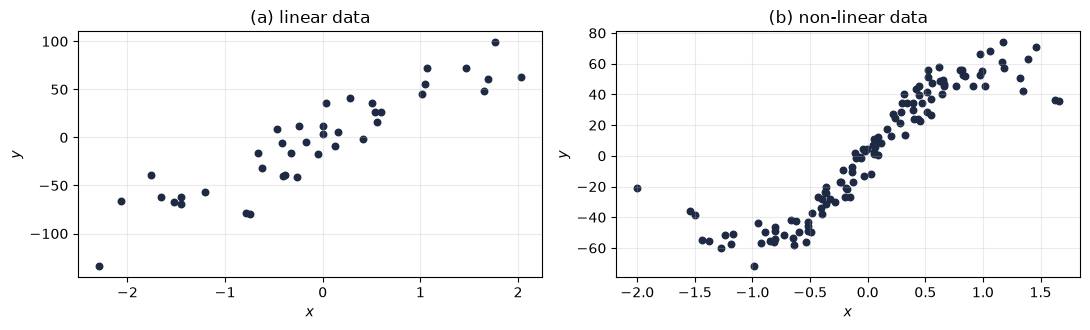

In [9]:
# ===== GIVEN — look at the two one-dimensional datasets =====
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].scatter(x_lin, y_lin, s=22, color=UOW["navy"])
axes[0].set(title="(a) linear data", xlabel="$x$", ylabel="$y$")
axes[1].scatter(x_nl, y_nl, s=22, color=UOW["navy"])
axes[1].set(title="(b) non-linear data", xlabel="$x$", ylabel="$y$")
plt.tight_layout(); plt.show()

---
# Q1 — Regression: maximum likelihood, maximum a posteriori and regularisation  *(40 marks)*

From the lecture: with Gaussian noise, $y^{(i)} = \mathbf{w}^\top\boldsymbol{\phi}(x^{(i)}) + \varepsilon^{(i)}$,
$\varepsilon^{(i)}\sim\mathcal{N}(0,\sigma^2)$,

$$\hat{\mathbf{w}}_{\text{MLE}} = (\Phi^\top\Phi)^{-1}\Phi^\top\mathbf{y},
\qquad
\hat{\mathbf{w}}_{\text{MAP}} = \Big(\Phi^\top\Phi + \tfrac{\sigma^2}{\tau^2}I\Big)^{-1}\Phi^\top\mathbf{y}$$

where $\Phi$ is the design matrix of basis functions, $\sigma^2$ is the noise variance and the prior is
$\mathbf{w}\sim\mathcal{N}(\mathbf{0}, \tau^2 I)$. The MAP estimate **is** ridge regression with
$\lambda = \sigma^2/\tau^2$ — you will see that on the numbers, not just on the slide.

### Task 1.1 — Implement the two estimators *(6 marks)*

Write the two functions below **from the equations**, using `numpy` only (`np.linalg.solve` or
`np.linalg.lstsq`; do not call scikit-learn inside them). `poly_design` builds the design matrix
$\Phi = [\,\mathbf{1},\, x,\, x^2,\, \dots,\, x^d\,]$.

**Notes for myself**: The +1 includes the power-zero column, where \(x^0=1\). This column of ones allows the model to learn the constant term(intercept) 

The resulting design matrix has \(d+1\) columns:$\Phi = [\,\mathbf{1},\, x,\, x^2,\, \dots,\, x^d\,]$. As mentioned above.

Increasing=True # To arrange the powers in ascending order: \(1,x,x^2,x^3\).

In [ ]:
def poly_design(x, degree):
    # Design matrix with a bias column and powers of x up to `degree`
    x = np.asarray(x).ravel()
    Phi = np.vander(x, N=degree + 1, increasing=True)
    
    return Phi 

def fit_mle(Phi, y):
    # Maximum-likelihood weights: argmin ||y - Phi w||^2
    mle = np.linalg.lstsq(Phi, y, rcond=None)

    return mle[0]

def fit_map(Phi, y, sigma2, tau2):
    # MAP weights under a N(0, tau2 I) prior and Gaussian noise of variance sigma2
    # lambda = sigma2 / tau2, then solve (Phi^T Phi + lambda I) w = Phi^T y
    lambda_value = sigma2 / tau2

    # Creating an identity matrix matching the number of coefficients
    identity = np.eye(Phi.shape[1])

    A = Phi.T @ Phi + lambda_value * identity
    b = Phi.T @ y
    
    # Solve for all coefficients
    weights = np.linalg.solve(A, b)
    
    return weights

In [58]:
# ===== SELF-CHECK 1.1 — your estimators against scikit-learn =====
Phi_chk = poly_design(x_lin, 3)
assert Phi_chk.shape == (len(x_lin), 4), "  should return one column per power, including the bias."

w_mle_chk = fit_mle(Phi_chk, y_lin)
sk_mle = LinearRegression(fit_intercept=False).fit(Phi_chk, y_lin).coef_
assert np.allclose(w_mle_chk, sk_mle, atol=1e-6), "fit_mle disagrees with LinearRegression."

sigma2_chk, tau2_chk = 100.0, 10.0          # lambda = 10
w_map_chk = fit_map(Phi_chk, y_lin, sigma2_chk, tau2_chk)
sk_map = Ridge(alpha=sigma2_chk / tau2_chk, fit_intercept=False).fit(Phi_chk, y_lin).coef_
assert np.allclose(w_map_chk, sk_map, atol=1e-6), \
    "fit_map disagrees with Ridge(alpha=sigma2/tau2, fit_intercept=False) — check the lambda."
print("Self-check 1.1 passed: MLE matches LinearRegression and MAP matches Ridge with lambda = {:.1f}".format(
    sigma2_chk / tau2_chk))

Self-check 1.1 passed: MLE matches LinearRegression and MAP matches Ridge with lambda = 10.0


### Task 1.2 — Linear data: MLE, MAP and the effect of the prior *(8 marks)*

Using dataset **(a)** and a degree-1 design matrix:

1. fit `fit_mle` and `fit_map` (start with $\sigma^2 = 18^2$, the noise variance the data was generated with, and $\tau^2 = 1$);
2. plot the data with both fitted lines;
3. build `prior_table`: for $\tau^2 \in \{0.01, 0.1, 1, 10, 100, 10^4\}$, record $\lambda = \sigma^2/\tau^2$, the fitted slope, and the training RMSE;
4. compare the slopes with the true slope `w_true_lin`.

MLE weights: [-0.59083431 43.61618017]
MAP weights: [-0.48561303  5.42480347]


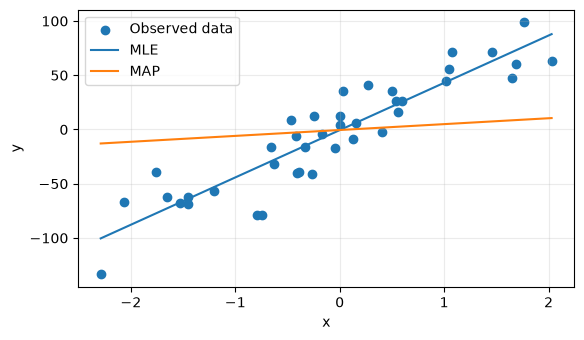

true slope: 41.29918291138346
MLE slope: 43.61618016864875


,lambda,intercept,slope,train_RMSE
tau2,,,,
0.01,32400.0000,-0.006112,0.061923,51.088850
0.10,3240.0000,-0.059775,0.611362,50.544812
1.00,324.0000,-0.485613,5.424803,45.838531
10.00,32.4000,-1.326608,25.555977,28.207357
100.00,3.2400,-0.814315,40.728662,20.787124
10000.00,0.0324,-0.593453,43.585260,20.557100


In [74]:
sigma2 = 18.0 ** 2
Phi_lin = poly_design(x_lin, 1)

# 1) fit MLE and MAP weights; 
w_mle_lin = fit_mle(Phi_lin, y_lin)
w_map_lin = fit_map(Phi_lin, y_lin, sigma2, tau2=1.0)

print("MLE weights:", w_mle_lin)
print("MAP weights:", w_map_lin)

# 2) plot the data and both fitted lines;
# Generating 200 evenly spaced points to plot the fitted regression lines,
# following the approach shown in Matplotlib's documentation (Matplotlib Development Team, 2026).
x_plot = np.linspace(x_lin.min(), x_lin.max(), 200)

Phi_plot = poly_design(x_plot, 1)

plt.figure()
plt.scatter(x_lin.ravel(), y_lin, label="Observed data")

for label, weights in [("MLE", w_mle_lin), ("MAP", w_map_lin)]:
    plt.plot(x_plot, Phi_plot @ weights, label=label)

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

# 3) build `prior_table` (index tau2; columns lambda, intercept, slope, train_RMSE)
#Checking how different prior variances affect the MAP weights

rows = []

for tau2 in [0.01, 0.1, 1, 10, 100, 1e4]:
    weights = fit_map(Phi_lin, y_lin, sigma2, tau2)

    # Predictions for the original training observations
    predictions = Phi_lin @ weights

    rows.append({
        "tau2": tau2,
        "lambda": sigma2 / tau2,
        "intercept": weights[0],
        "slope": weights[1],
        "train_RMSE": root_mean_squared_error(y_lin, predictions)
    })

prior_table = pd.DataFrame(rows).set_index("tau2")

print("true slope:", float(w_true_lin))
print("MLE slope:", w_mle_lin[1])
prior_table

In [66]:
# ===== SELF-CHECK 1.2 =====
assert prior_table is not None and len(prior_table) == 6, "prior_table needs one row per tau2."
assert prior_table["lambda"].is_monotonic_decreasing, "lambda = sigma2 / tau2 falls as tau2 grows."
assert abs(prior_table["slope"].iloc[-1] - w_mle_lin[1]) < 1.0, \
    "With a very weak prior (large tau2) the MAP slope should approach the MLE slope."
assert abs(prior_table["slope"].iloc[0]) < abs(w_mle_lin[1]), \
    "With a very strong prior (small tau2) the slope should be shrunk towards zero."
print("Self-check 1.2 passed.")

Self-check 1.2 passed.


In [ ]:
# Supporting evidence for the question below "Which end of the table corresponds to ordinary least squares?" 
w_mle_lin = fit_mle(Phi_lin, y_lin)
w_ols_lin = np.linalg.lstsq(Phi_lin, y_lin, rcond=None)[0]

print("OLS weights:", w_ols_lin)
print("MLE weights:", w_mle_lin)

print("Are they equivalent?",
      np.allclose(w_ols_lin, w_mle_lin))

OLS weights: [-0.59083431 43.61618017]
MLE weights: [-0.59083431 43.61618017]
Are they equivalent? True


#### ✏️ Written answer 1.2 *(part of the 8 marks)* — replace this text

**what happens to the slope as $\tau^2$ goes from $0.01$ to $10^4$, and why?**

The noise variance $\sigma^2$ is fixed at 324, resulting in a regularisation parameter of $\lambda = \sigma^2/\tau^2$. As the prior variance $\tau^2$ increases, the strength of regularisation decreases, which enables the MAP weights to converge towards the MLE estimates. In contrast, smaller prior variances increase the strength of regularisation, drawing the weights closer to zero. Mathematically, as $\tau^2$ approaches infinity, $\lambda$ approaches zero, and MAP converges to MLE.

**Which end of the table corresponds to ordinary least squares (OLS)?**

The bottom of the table, where $\tau^2=10^4$. Here, $\lambda=0.0324$, so the penalty is very small. Also, the MAP slope of 43.585 is close to the MLE/OLS slope of 43.616. It approaches OLS as $\tau^2$ grows.

**Which to "I am almost certain the weights are zero"?**

The top of the table, where $\tau^2=0.01$. The large penalty, $\lambda=32400$, pulls the coefficients towards zero and produces a slope of approximately 0.062.

### Task 1.3 — Non-linear data: where MLE overfits *(8 marks)*

Dataset **(b)** is curved, so a straight line cannot fit it — but a **polynomial basis** turns it into a linear
model in the weights.

1. Split the 120 points into train (80) and validation (40) with `train_test_split` and `RANDOM_STATE`.
2. For degrees 1, 3 and 9, fit **MLE** and **MAP** ($\sigma^2 = 64$, i.e. the noise the data was generated with, and $\tau^2 = 100$) on the training rows, and record train and validation RMSE in `poly_table`.
3. Plot the data and the degree-9 fitted curves, MLE against MAP.
4. Read the table: store the best (degree, estimator) pair in `best_choice` — the smallest **validation** RMSE anywhere in the table.

You should find that a modest basis wins outright. Question 1.5 asks you what the prior is *for*, given that.

In [ ]:
xtr_nl, xva_nl, ytr_nl, yva_nl = train_test_split(
    x_nl, y_nl, test_size=40, random_state=RANDOM_STATE)

sigma2_nl, tau2_nl = 64.0, 100.0
degrees = [1, 3, 9]

# ===== YOUR CODE HERE =====
# Build `poly_table` (index degree; columns MLE_train, MLE_val, MAP_train, MAP_val),
# plot the data and the degree-9 MLE and MAP curves, and set `best_choice`
# to the (degree, "MLE" or "MAP") pair with the lowest validation RMSE.
poly_table = None
best_choice = None
# ===== END OF YOUR CODE =====

poly_table

In [ ]:
# ===== SELF-CHECK 1.3 =====
assert poly_table is not None and list(poly_table.index) == degrees, "One row per degree, please."
assert poly_table.loc[9, "MLE_train"] < poly_table.loc[1, "MLE_train"], \
    "A richer basis must fit the training data better."
assert poly_table.loc[9, "MLE_val"] > 3 * poly_table.loc[9, "MAP_val"], \
    "At degree 9 the unregularised fit should be far worse on validation than the MAP fit."
assert best_choice is not None and best_choice[0] in degrees, "Set `best_choice` from the table."
assert best_choice[0] != 9, \
    "The richest basis should not win: the prior limits the damage, it does not beat a sensible basis."
print(f"Self-check 1.3 passed: best on validation is degree {best_choice[0]} with {best_choice[1]}.")

### Task 1.4 — Many features: baseline, Ridge, Lasso and Elastic Net *(10 marks)*

Dataset **(c)** has 250 rows and 60 features, of which only **8** carry signal (`informative_idx`). This is the
regime the lecture called "regularisation earns its keep".

1. **Frame and split.** 60 / 20 / 20 with `RANDOM_STATE`. State in one line why there is no leakage risk in how you split.
2. **Pipeline.** `StandardScaler` **inside** a `Pipeline` with the model, so the scaler is fitted on training rows only.
3. **Baseline.** `DummyRegressor(strategy="mean")` and `LinearRegression`.
4. **Regularised models.** Ridge and Lasso over `alphas`, plus an Elastic Net over a small grid; choose each λ on **validation**.
5. Collect everything in `results_many` and set `best_model_name`.
6. **Sparsity.** For your chosen Lasso, report how many coefficients are non-zero and how many of the 8 informative features it recovered.

In [ ]:
alphas = np.logspace(-3, 3, 25)

# ===== YOUR CODE HERE =====
# 1) 60/20/20 split into Xm_train / Xm_val / Xm_test (+ ym_*)
# 2) a helper that builds Pipeline([StandardScaler, estimator]) and scores it on validation
# 3) validation curves for Ridge and Lasso over `alphas`; a small Elastic Net grid
# 4) `results_many` (index model; columns train_RMSE, val_RMSE, val_R2) for
#    dummy, ols, ridge, lasso, elastic_net, and `best_model_name`
# 5) report how many Lasso coefficients are non-zero and how many of `informative_idx` are recovered
Xm_train = Xm_val = Xm_test = None
ym_train = ym_val = ym_test = None
best_alpha_ridge = best_alpha_lasso = None
results_many = None
best_model_name = None
selected = recovered = None
# ===== END OF YOUR CODE =====

results_many

In [ ]:
# ===== SELF-CHECK 1.4 =====
assert results_many is not None and len(results_many) == 5, "results_many should have five rows."
assert results_many.loc["ols", "val_RMSE"] < results_many.loc["dummy", "val_RMSE"], \
    "Every real model should beat the mean baseline."
assert results_many.loc["lasso", "val_RMSE"] < results_many.loc["ols", "val_RMSE"], \
    "On 150 training rows and 60 features, Lasso should beat unregularised OLS."
assert len(selected) < 60, "Lasso should set at least some coefficients to exactly zero."
assert len(recovered) >= 6, "Your Lasso should recover most of the 8 informative features."
print(f"Self-check 1.4 passed: {len(selected)} features kept, {len(recovered)} informative ones recovered.")

#### ✏️ Written answer 1.5 *(8 marks)* — replace this text

Answer all four, quoting your own numbers:

1. Explain in two or three sentences why maximising the Gaussian likelihood gives the same weights as minimising the sum of squared errors, and what changes when a Gaussian prior is added.
2. Using Task 1.3: which (degree, estimator) pair won, and by how much? Then, given that a modest basis already wins, explain what the prior is **for** — refer to the degree-9 column, and to Task 1.4, where you cannot simply choose a smaller basis.
3. Using Task 1.4: which model won on validation, by how much, and what did Lasso's sparsity tell you about the 60 features?
4. If the noise were heavier-tailed than Gaussian, which part of the argument in (1) breaks, and what loss would replace the squared error?

*(250–350 words)*

*Your answer here.*

---
# Q2 — Logistic regression with class imbalance  *(40 marks)*

Dataset **(d)**: 12,000 rows, 20 features, about **8%** positive. Read it as a screening problem — a positive
case is a customer about to churn, a machine about to fail, or a patient at risk — where **missing a positive
costs far more than a false alarm**.

### Task 2.1 — Framing, split and a first model *(6 marks)*

1. Make a **stratified** 60 / 20 / 20 split of `X_clf`, `y_clf`.
2. Fit a `DummyClassifier(strategy="most_frequent")` and a plain `LogisticRegression` inside a pipeline with `StandardScaler`.
3. Report accuracy, precision, recall and the number of predicted positives on validation in `results_baseline`.

In [ ]:
# ===== YOUR CODE HERE =====
# 1) stratified 60/20/20 split -> Xc_train / Xc_val / Xc_test and yc_train / yc_val / yc_test
# 2) a `clf_scores(model, X_, y_)` helper returning accuracy, precision, recall, n_pred_positive
# 3) fit the dummy and the plain logistic pipeline; build `results_baseline`
Xc_train = Xc_val = Xc_test = None
yc_train = yc_val = yc_test = None
dummy_clf = logreg_plain = None
results_baseline = None
# ===== END OF YOUR CODE =====

results_baseline

In [ ]:
# ===== SELF-CHECK 2.1 =====
assert results_baseline is not None and len(results_baseline) == 2, "Two rows, please."
assert abs(yc_train.mean() - yc_val.mean()) < 0.01, "The split should be stratified."
assert results_baseline.loc["dummy", "recall"] == 0, "A majority-class dummy has zero recall."
assert results_baseline.loc["dummy", "accuracy"] > 0.85, "...and yet high accuracy. That is the point."
print("Self-check 2.1 passed.")

### Task 2.2 — Metrics that respect the minority class *(8 marks)*

For the plain logistic model, on validation:

1. compute **ROC-AUC** and **PR-AUC** (`average_precision_score`), and state the no-skill value of each;
2. plot the ROC curve and the precision–recall curve side by side, marking both no-skill lines.

In [ ]:
# ===== YOUR CODE HERE =====
# Compute roc_auc and pr_auc on validation for `logreg_plain`, then plot the ROC and PR curves
# side by side with their no-skill lines.
proba_val = None
roc_auc = pr_auc = None
# ===== END OF YOUR CODE =====

print("ROC-AUC:", roc_auc, "| PR-AUC:", pr_auc)

In [ ]:
# ===== SELF-CHECK 2.2 =====
assert roc_auc is not None and pr_auc is not None, "Compute both metrics."
assert roc_auc > pr_auc, "With a rare positive class ROC-AUC flatters the model relative to PR-AUC."
assert pr_auc > yc_val.mean(), "PR-AUC should beat the no-skill level, which is the positive rate."
print(f"Self-check 2.2 passed: ROC-AUC {roc_auc:.3f} vs PR-AUC {pr_auc:.3f} (no-skill {yc_val.mean():.3f}).")

### Task 2.3 — Class weights against resampling *(10 marks)*

Fit two more models on the training rows and compare all three on validation in `results_imbalance`
(accuracy, precision, recall, `n_pred_positive` and PR-AUC):

* `logreg_weighted` — `LogisticRegression(class_weight="balanced")`
* `logreg_smote` — an **`imblearn`** pipeline: `StandardScaler` → `SMOTE(random_state=RANDOM_STATE)` → `LogisticRegression`

The sampler must sit **inside** the pipeline so that it only ever sees training rows; the validation set must
keep its real 8% positive rate.

When you read the table, look at the **PR-AUC column and the recall column separately**, and ask whether the
PR-AUC differences are large enough to mean anything on ~200 validation positives. Question 2.5 asks about
this.

In [ ]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# ===== YOUR CODE HERE =====
# Fit `logreg_weighted` and `logreg_smote`, then build `results_imbalance` with one row per model
# (plain, class_weight, smote) and a PR_AUC column.
logreg_weighted = logreg_smote = None
results_imbalance = None
# ===== END OF YOUR CODE =====

results_imbalance

In [ ]:
# ===== SELF-CHECK 2.3 =====
assert results_imbalance is not None and len(results_imbalance) == 3, "Three rows, please."
assert results_imbalance.loc["class_weight", "recall"] > results_imbalance.loc["plain", "recall"], \
    "Class weighting should raise recall at the default 0.5 threshold."
assert results_imbalance.loc["class_weight", "n_pred_positive"] > results_imbalance.loc["plain", "n_pred_positive"], \
    "...by flagging more cases."
print("Self-check 2.3 passed.")

### Task 2.4 — Choosing the operating threshold *(8 marks)*

The business rule: **a missed positive costs 10 units, a false alarm costs 1 unit.**

Pick the model to take forward by this rule: **take the best PR-AUC, unless the models are within 0.02 of each
other, in which case prefer the simplest one** (plain < class weighting < SMOTE) and say why in 2.5. A
difference in the third decimal on ~200 positives is not evidence.

Using validation probabilities from the model you chose:

1. sweep the thresholds from the precision–recall curve and compute the expected cost
   $10 \times FN + 1 \times FP$ at each;
2. store the cost-minimising threshold in `chosen_threshold`;
3. print the confusion matrix and the classification report at that threshold, and compare the cost there with the cost at the default 0.5.

In [ ]:
C_FN, C_FP = 10.0, 1.0

# ===== YOUR CODE HERE =====
# 1) apply the selection rule above (best PR-AUC, or the simplest model within 0.02 of it)
#    and get its validation probabilities
# 2) sweep thresholds, computing 10*FN + 1*FP at each, and plot cost against threshold
# 3) set `chosen_threshold` to the cost-minimising value
# 4) print the confusion matrix and classification_report there, and compare the cost with t = 0.5
best_clf_name = best_clf = None
chosen_threshold = None
# ===== END OF YOUR CODE =====

In [ ]:
# ===== SELF-CHECK 2.4 =====
assert chosen_threshold is not None and 0 < chosen_threshold < 1, "A probability threshold lies in (0, 1)."
assert best_clf_name is not None, "Record which model you took forward in `best_clf_name`."
assert results_imbalance["PR_AUC"].max() - results_imbalance.loc[best_clf_name, "PR_AUC"] <= 0.02, \
    "The model you took forward is clearly worse than the best one — re-read the selection rule."
_p = best_clf.predict_proba(Xc_val)[:, 1]
_tn, _fp, _fn, _tp = confusion_matrix(yc_val, (_p >= chosen_threshold).astype(int)).ravel()
_tn0, _fp0, _fn0, _tp0 = confusion_matrix(yc_val, (_p >= 0.5).astype(int)).ravel()
assert 10 * _fn + _fp <= 10 * _fn0 + _fp0, "Your threshold should not be worse than the default on cost."
print(f"Self-check 2.4 passed: cost {10 * _fn + _fp:.0f} at t={chosen_threshold:.2f} "
      f"versus {10 * _fn0 + _fp0:.0f} at t=0.5.")

### Final check — the test set, used once *(part of Task 2.4)*

Refit your chosen model on **train + validation**, then evaluate once on the test set at `chosen_threshold`.

In [ ]:
# ===== YOUR CODE HERE =====
# Refit the chosen model on train + validation, then evaluate ONCE on the test set at
# `chosen_threshold`. Build `test_report` with PR-AUC, ROC-AUC, precision, recall, cost and the
# threshold, and print the confusion matrix.
final_model = None
test_report = None
# ===== END OF YOUR CODE =====

print(pd.Series(test_report).round(4).to_string())

#### ✏️ Written answer 2.5 *(8 marks)* — replace this text

Answer all four, quoting your own numbers:

1. The dummy classifier's accuracy is higher than you might expect. Give its accuracy and recall, and explain in one sentence why accuracy is the wrong headline metric here.
2. Your ROC-AUC and PR-AUC differ substantially. Explain why, and say which you would put in a report for a manager.
3. Class weighting and SMOTE: what did each change, and what did neither change? Are the PR-AUC differences in `results_imbalance` big enough to choose between the three models, on ~200 validation positives? Which did you take forward, and why?
4. Justify your threshold in terms of the 10:1 cost. How would it move if false alarms became much more expensive, and what would you monitor after deployment?

*(250–350 words)*

*Your answer here.*

---
# Q3 — Commentary and reflection  *(20 marks)*

#### ✏️ Written answer — replace this text

Write **400–500 words**, using the headings below.

**Approach (5 marks).** The decisions you made across Q1 and Q2 and why: basis functions and prior in Q1,
the choice of λ, the metric and threshold in Q2.

**Key results (5 marks).** Your headline numbers, each against its baseline: regression RMSE against the dummy,
PR-AUC against the positive rate, cost at your threshold against cost at 0.5.

**Limitations (5 marks).** What this analysis does **not** establish. At least one point must concern the data
being synthetic and drawn from a known generative process, and one the single train/validation split.

**Next step (5 marks).** The one change you would make first with another week, and what you expect it to buy
you. Be specific — "use cross-validation" earns little without saying what it would change about your
conclusions.

*Your answer here.*

#### Declaration of generative AI use

State which tools you used, for what, and how you verified the output. Write "None" if you used none.

*Your declaration here.*

---
## Before you submit

Run `Kernel ▸ Restart & Run All`, check that every cell executes and every plot appears, then run the cell below.

In [ ]:
# ===== SUBMISSION CHECK =====
checks = {
    "Q1.1 estimators implemented": callable(fit_mle) and callable(fit_map),
    "Q1.2 prior table": prior_table is not None,
    "Q1.3 polynomial table": poly_table is not None,
    "Q1.4 model comparison": results_many is not None,
    "Q2.1 baseline table": results_baseline is not None,
    "Q2.2 both AUCs": roc_auc is not None and pr_auc is not None,
    "Q2.3 imbalance table": results_imbalance is not None,
    "Q2.4 threshold chosen": chosen_threshold is not None,
    "Q2.4 test evaluated once": test_report is not None,
}
for k, v in checks.items():
    print(("PASS  " if v else "TODO  ") + k)
print("\nRemember: the written answers carry 36 of the 100 marks (1.2, 1.5, 2.5 and Q3).")

**References**:

Matplotlib Development Team (2026) Getting started. Matplotlib documentation. Available at: https://matplotlib.org/stable/users/getting_started/ (Accessed: 25 October 2026).